# Statistiek week 4

## Data importeren

In [1]:
import openpyxl

In [2]:
import pandas as pd

In [3]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [4]:
rel_data_path = "/content/drive/MyDrive/Creditcardtransacties_RZ.xlsx"

In [9]:
creditcard_transacties = pd.read_excel(rel_data_path)
creditcard_transacties

,TransactieID,Datum,Bedrag (€),Tijdstip,Locatie,Bedrag_Categorie,Aankoopfrequentie,Afstand_van_huis (km)
0,T001,2024-01-01,45.50,14:30:00,Amsterdam,2,3,5.2
1,T002,2024-01-01,125.00,09:15:00,Rotterdam,3,2,12.8
2,T003,2024-01-01,15.75,19:45:00,Utrecht,1,5,8.3
3,T004,2024-01-02,2300.00,02:15:00,Milaan,5,1,1850.0
4,T005,2024-01-02,67.30,11:20:00,Den Haag,2,4,15.6
5,T006,2024-01-02,89.99,16:45:00,Amsterdam,3,3,5.1
6,T007,2024-01-03,34.20,13:10:00,Rotterdam,1,6,13.1
7,T008,2024-01-03,156.75,20:30:00,Utrecht,3,2,8.5
8,T009,2024-01-03,12.50,08:45:00,Amsterdam,1,7,5.0
9,T010,2024-01-04,450.00,23:55:00,Barcelona,4,1,1200.0


## Analyse en Berekeningen - Z-scores
We gaan nu de basisstatistieken berekenen, de Z-scores bepalen, en verdachte transacties identificeren.
```

In [10]:
import numpy as np

# 1. Basisstatistieken berekenen voor 'Bedrag (€)'
mean_bedrag = creditcard_transacties['Bedrag (€)'].mean()
std_bedrag = creditcard_transacties['Bedrag (€)'].std()
median_bedrag = creditcard_transacties['Bedrag (€)'].median()
min_bedrag = creditcard_transacties['Bedrag (€)'].min()
max_bedrag = creditcard_transacties['Bedrag (€)'].max()

basis_stats = pd.DataFrame({
    'Statistiek': ['Gemiddelde', 'Standaardafwijking', 'Mediaan', 'Minimum', 'Maximum'],
    'Waarde (€)': [mean_bedrag, std_bedrag, median_bedrag, min_bedrag, max_bedrag]
})

print("--- Basisstatistieken ---")
display(basis_stats)

--- Basisstatistieken ---


,Statistiek,Waarde (€)
0,Gemiddelde,286.043200
1,Standaardafwijking,543.385998
2,Mediaan,67.300000
3,Minimum,3.500000
4,Maximum,2300.000000


In [11]:
# 2. Z-scores berekenen voor alle transacties
creditcard_transacties['Z-score'] = (creditcard_transacties['Bedrag (€)'] - mean_bedrag) / std_bedrag

print("--- Eerste transacties met Z-score ---")
display(creditcard_transacties.head())

--- Eerste transacties met Z-score ---


,TransactieID,Datum,Bedrag (€),Tijdstip,Locatie,Bedrag_Categorie,Aankoopfrequentie,Afstand_van_huis (km),Z-score
0,T001,2024-01-01,45.50,14:30:00,Amsterdam,2,3,5.2,-0.442675
1,T002,2024-01-01,125.00,09:15:00,Rotterdam,3,2,12.8,-0.296370
2,T003,2024-01-01,15.75,19:45:00,Utrecht,1,5,8.3,-0.497424
3,T004,2024-01-02,2300.00,02:15:00,Milaan,5,1,1850.0,3.706310
4,T005,2024-01-02,67.30,11:20:00,Den Haag,2,4,15.6,-0.402556


In [12]:
# 3. Identificeer verdachte transacties (Z > 2 en Z > 3)
verdacht_z2 = creditcard_transacties[creditcard_transacties['Z-score'] > 2]
verdacht_z3 = creditcard_transacties[creditcard_transacties['Z-score'] > 3]

print(f"--- Verdachte transacties (Z > 2): {len(verdacht_z2)} gevonden ---")
display(verdacht_z2)

print(f"\n--- Verdachte transacties (Z > 3): {len(verdacht_z3)} gevonden ---")
display(verdacht_z3)

--- Verdachte transacties (Z > 2): 2 gevonden ---


,TransactieID,Datum,Bedrag (€),Tijdstip,Locatie,Bedrag_Categorie,Aankoopfrequentie,Afstand_van_huis (km),Z-score
3,T004,2024-01-02,2300.0,02:15:00,Milaan,5,1,1850.0,3.70631
19,T020,2024-01-09,1500.0,14:00:00,Parijs,5,1,500.0,2.23406



--- Verdachte transacties (Z > 3): 1 gevonden ---


,TransactieID,Datum,Bedrag (€),Tijdstip,Locatie,Bedrag_Categorie,Aankoopfrequentie,Afstand_van_huis (km),Z-score
3,T004,2024-01-02,2300.0,02:15:00,Milaan,5,1,1850.0,3.70631


## Multivariate Analyse (Mahalanobis-afstand)
We analyseren de relaties tussen de numerieke kolommen `Bedrag (€)`, `Aankoopfrequentie`, en `Afstand_van_huis (km)` en berekenen de Mahalanobis-afstand om multivariate uitschieters op te sporen.
```

In [14]:
import numpy as np
import pandas as pd
from scipy.stats import chi2

# 1. Analyseer correlaties tussen numerieke features
features = ['Bedrag (€)', 'Aankoopfrequentie', 'Afstand_van_huis (km)']
correlatiematrix = creditcard_transacties[features].corr()

print("--- Correlatiematrix tussen features ---")
display(correlatiematrix)

--- Correlatiematrix tussen features ---


,Bedrag (€),Aankoopfrequentie,Afstand_van_huis (km)
Bedrag (€),1.000000,-0.535445,0.442031
Aankoopfrequentie,-0.535445,1.000000,-0.385154
Afstand_van_huis (km),0.442031,-0.385154,1.000000


In [15]:
# 2. Bereken Mahalanobis-afstanden voor alle transacties
def bereken_mahalanobis(df, columns):
    df_data = df[columns]
    cov_matrix = np.cov(df_data.values.T)
    inv_cov_matrix = np.linalg.inv(cov_matrix)
    mean_vals = df_data.mean().values

    mahalanobis_dist = []
    for i, row in df_data.iterrows():
        diff = row.values - mean_vals
        mahal_d2 = diff.dot(inv_cov_matrix).dot(diff)
        mahalanobis_dist.append(np.sqrt(mahal_d2))
    return mahalanobis_dist

creditcard_transacties['Mahalanobis_Afstand'] = bereken_mahalanobis(creditcard_transacties, features)

# Bepaal drempelwaarde op basis van Chi-kwadraat verdeling (p < 0.01 met df=3)
df_degrees = len(features)
threshold_chi2 = np.sqrt(chi2.ppf(0.99, df_degrees))

print(f"Kritieke Mahalanobis drempelwaarde (Chi-kwadraat p < 0.01): {threshold_chi2:.4f}")

Kritieke Mahalanobis drempelwaarde (Chi-kwadraat p < 0.01): 3.3682


In [16]:
# 3. Identificeer multivariate outliers
multivariate_outliers = creditcard_transacties[creditcard_transacties['Mahalanobis_Afstand'] > threshold_chi2]

print(f"--- Multivariate Outliers ({len(multivariate_outliers)} gevonden) ---")
display(multivariate_outliers)

--- Multivariate Outliers (2 gevonden) ---


,TransactieID,Datum,Bedrag (€),Tijdstip,Locatie,Bedrag_Categorie,Aankoopfrequentie,Afstand_van_huis (km),Z-score,Mahalanobis_Afstand
3,T004,2024-01-02,2300.0,02:15:00,Milaan,5,1,1850.0,3.706310,3.855308
24,T025,2024-01-11,650.0,19:20:00,New York,5,1,5800.0,0.669794,4.697838


## Geïntegreerde Risicoscore en Aanbevelingen
We combineren de univariate risico's (Z-score op basis van het bedrag) en multivariate risico's (Mahalanobis-afstand) tot één geïntegreerde risicoscore.
```

In [17]:
# 1. Ontwikkel een gecombineerde risicoscore
# We normaliseren de Z-score (absolute waarde) en de Mahalanobis-afstand en nemen het gewogen gemiddelde.
abs_z = creditcard_transacties['Z-score'].abs()
mahal = creditcard_transacties['Mahalanobis_Afstand']

# Risicoscore schalen tussen 0 en 100
norm_z = (abs_z - abs_z.min()) / (abs_z.max() - abs_z.min()) * 100
norm_mahal = (mahal - mahal.min()) / (mahal.max() - mahal.min()) * 100

creditcard_transacties['Risicoscore'] = (0.5 * norm_z) + (0.5 * norm_mahal)

# 2. Classificeer transacties in risicocategorieën
def bepaal_categorie(score):
    if score > 60:
        return 'Hoog'
    elif score > 20:
        return 'Medium'
    else:
        return 'Laag'

creditcard_transacties['Risicocategorie'] = creditcard_transacties['Risicoscore'].apply(bepaal_categorie)

# 3. Maak aanbevelingen voor actie
def genereer_aanbeveling(row):
    if row['Risicocategorie'] == 'Hoog':
        return "Transactie direct blokkeren en contact opnemen met de kaarthouder."
    elif row['Risicocategorie'] == 'Medium':
        return "Transactie handmatig controleren; stuur een verificatie-sms naar de kaarthouder."
    else:
        return "Geen actie vereist."

creditcard_transacties['Aanbeveling'] = creditcard_transacties.apply(genereer_aanbeveling, axis=1)

print("--- Eerste transacties met Risicoscore en Aanbeveling ---")
display(creditcard_transacties[['TransactieID', 'Bedrag (€)', 'Risicoscore', 'Risicocategorie', 'Aanbeveling']].head())

--- Eerste transacties met Risicoscore en Aanbeveling ---


,TransactieID,Bedrag (€),Risicoscore,Risicocategorie,Aanbeveling
0,T001,45.50,9.193727,Laag,Geen actie vereist.
1,T002,125.00,10.820856,Laag,Geen actie vereist.
2,T003,15.75,5.855622,Laag,Geen actie vereist.
3,T004,2300.00,89.956364,Hoog,Transactie direct blokkeren en contact opnemen...
4,T005,67.30,4.158445,Laag,Geen actie vereist.


## Resultaten opslaan naar Excel
We slaan de resultaten nu op in een nieuw Excel-bestand met verschillende tabbladen voor het overzicht.

In [13]:
output_path = "/content/drive/MyDrive/Transacties_Geanalyseerd.xlsx"

with pd.ExcelWriter(output_path, engine='openpyxl') as writer:
    # Schrijf alle transacties inclusief Z-scores
    creditcard_transacties.to_excel(writer, sheet_name='Alle Transacties', index=False)

    # Schrijf de basisstatistieken
    basis_stats.to_excel(writer, sheet_name='Basisstatistieken', index=False)

    # Schrijf de verdachte transacties
    verdacht_z2.to_excel(writer, sheet_name='Verdacht (Z gt 2)', index=False)
    verdacht_z3.to_excel(writer, sheet_name='Verdacht (Z gt 3)', index=False)

print(f"Het Excel-bestand is succesvol opgeslagen op: {output_path}")

Het Excel-bestand is succesvol opgeslagen op: /content/drive/MyDrive/Transacties_Geanalyseerd.xlsx


In [18]:
# Update het Excel-bestand met de nieuwe analyses
output_path_v2 = "/content/drive/MyDrive/Transacties_Multivariate_Risico_Analyse.xlsx"

with pd.ExcelWriter(output_path_v2, engine='openpyxl') as writer:
    # Schrijf alle transacties inclusief Z-scores, Mahalanobis en risicoclassificaties
    creditcard_transacties.to_excel(writer, sheet_name='Risico Analyse', index=False)

    # Schrijf de multivariate uitschieters
    multivariate_outliers.to_excel(writer, sheet_name='Multivariate Outliers', index=False)

    # Schrijf de transacties die handmatige controle of blokkade vereisen
    actie_vereist = creditcard_transacties[creditcard_transacties['Risicocategorie'].isin(['Medium', 'Hoog'])]
    actie_vereist.to_excel(writer, sheet_name='Actie Vereist', index=False)

print(f"Het uitgebreide Excel-bestand is opgeslagen op: {output_path_v2}")

Het uitgebreide Excel-bestand is opgeslagen op: /content/drive/MyDrive/Transacties_Multivariate_Risico_Analyse.xlsx


## Visueel Dashboard
We visualiseren de resultaten van de risicoanalyse in een overzichtelijk dashboard met matplotlib en seaborn.
```

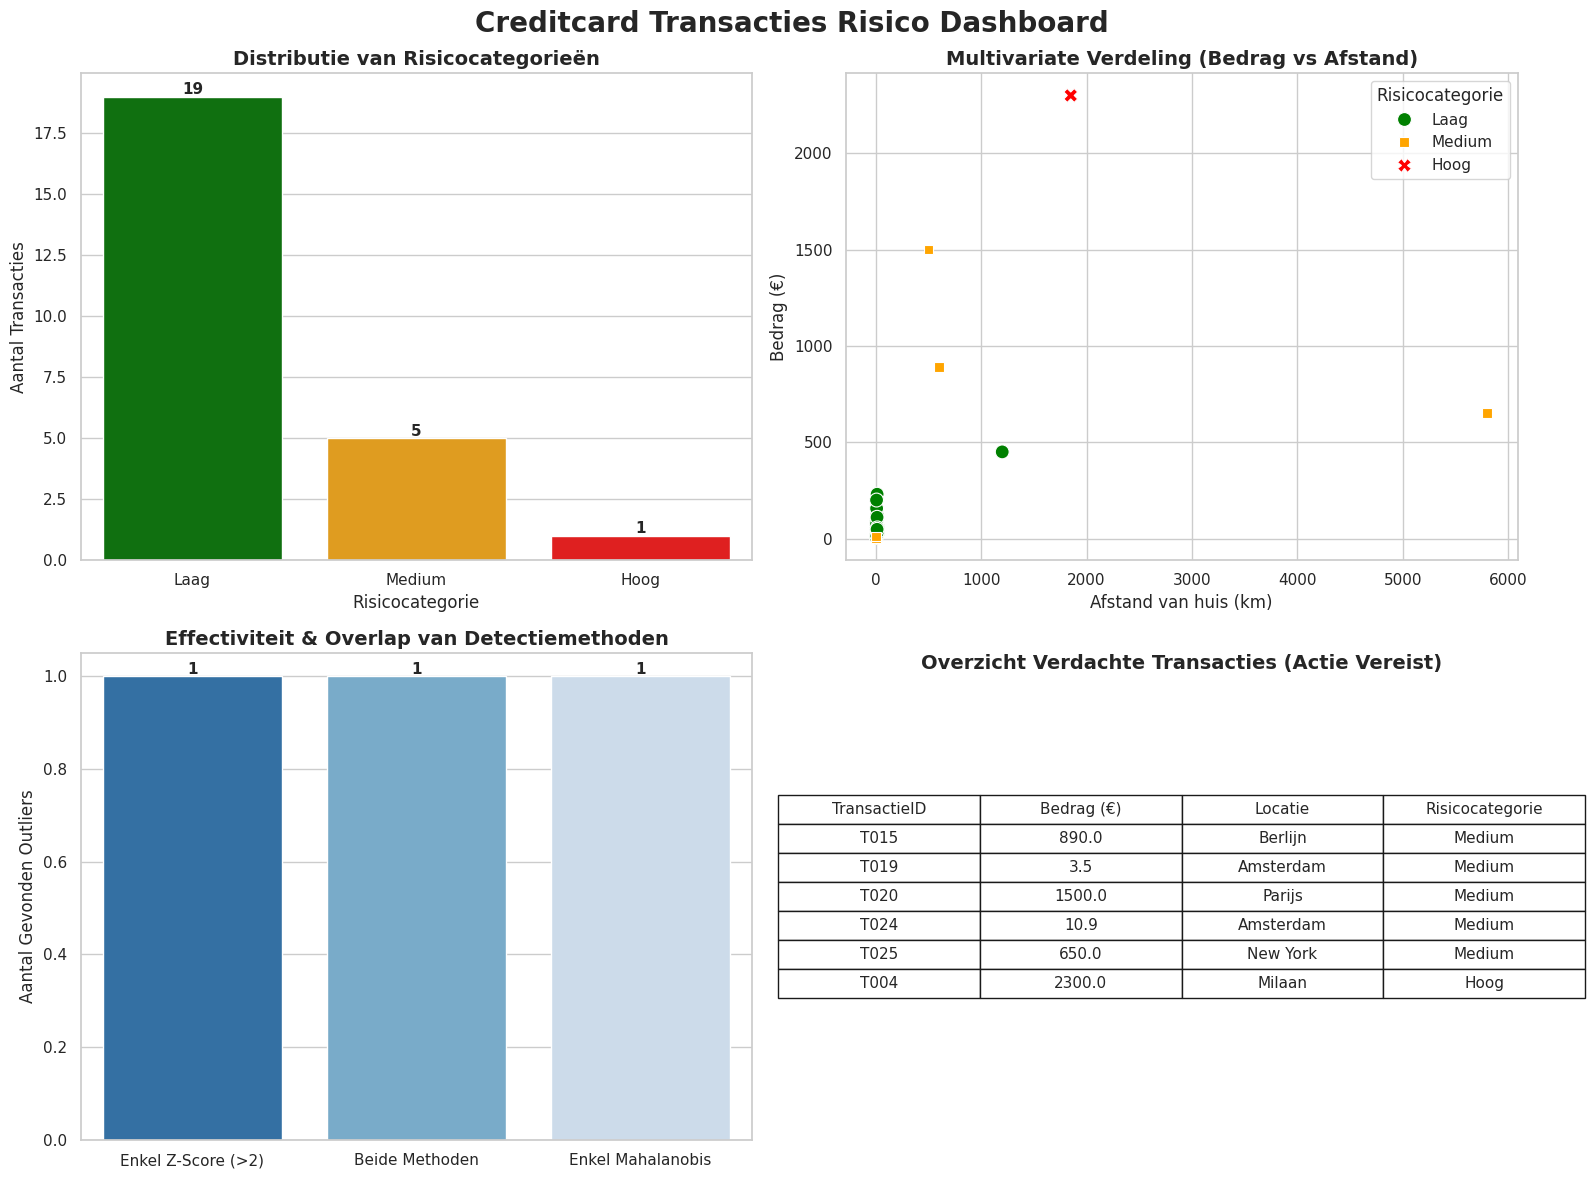

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Stel de stijl in voor nette visualisaties
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Creditcard Transacties Risico Dashboard', fontsize=20, weight='bold', y=0.98)

# 1. Risicodistributie (Barplot van risicocategorieën)
sns.countplot(
    ax=axes[0, 0],
    x='Risicocategorie',
    data=creditcard_transacties,
    order=['Laag', 'Medium', 'Hoog'],
    palette={'Laag': 'green', 'Medium': 'orange', 'Hoog': 'red'},
    hue='Risicocategorie',
    legend=False
)
axes[0, 0].set_title('Distributie van Risicocategorieën', fontsize=14, weight='bold')
axes[0, 0].set_xlabel('Risicocategorie')
axes[0, 0].set_ylabel('Aantal Transacties')
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=11, weight='bold')

# 2. Scatterplot van Bedrag vs Afstand met Risicomarkeringen
sns.scatterplot(
    ax=axes[0, 1],
    x='Afstand_van_huis (km)',
    y='Bedrag (€)',
    hue='Risicocategorie',
    style='Risicocategorie',
    palette={'Laag': 'green', 'Medium': 'orange', 'Hoog': 'red'},
    hue_order=['Laag', 'Medium', 'Hoog'],
    data=creditcard_transacties,
    s=100
)
axes[0, 1].set_title('Multivariate Verdeling (Bedrag vs Afstand)', fontsize=14, weight='bold')
axes[0, 1].set_xlabel('Afstand van huis (km)')
axes[0, 1].set_ylabel('Bedrag (€)')

# 3. Effectiviteit Analyse: Univariate vs Multivariate Outliers (Venn-achtig overzicht)
z_outliers_set = set(creditcard_transacties[creditcard_transacties['Z-score'].abs() > 2]['TransactieID'])
mahal_outliers_set = set(creditcard_transacties[creditcard_transacties['Mahalanobis_Afstand'] > threshold_chi2]['TransactieID'])

enkel_z = len(z_outliers_set - mahal_outliers_set)
enkel_mahal = len(mahal_outliers_set - z_outliers_set)
beide = len(z_outliers_set & mahal_outliers_set)

methods_df = pd.DataFrame({
    'Detectie Methode': ['Enkel Z-Score (>2)', 'Beide Methoden', 'Enkel Mahalanobis'],
    'Aantal Outliers': [enkel_z, beide, enkel_mahal]
})

sns.barplot(
    ax=axes[1, 0],
    x='Detectie Methode',
    y='Aantal Outliers',
    data=methods_df,
    palette='Blues_r',
    hue='Detectie Methode',
    legend=False
)
axes[1, 0].set_title('Effectiviteit & Overlap van Detectiemethoden', fontsize=14, weight='bold')
axes[1, 0].set_ylabel('Aantal Gevonden Outliers')
axes[1, 0].set_xlabel('')
for p in axes[1, 0].patches:
    axes[1, 0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=11, weight='bold')

# 4. Tabel van Hoog & Medium Risico Transacties
axes[1, 1].axis('off')
actie_tabel_data = creditcard_transacties[creditcard_transacties['Risicocategorie'].isin(['Medium', 'Hoog'])][['TransactieID', 'Bedrag (€)', 'Locatie', 'Risicocategorie']]
actie_tabel_data = actie_tabel_data.sort_values(by='Risicocategorie', ascending=False) # Hoog bovenaan

table = axes[1, 1].table(
    cellText=actie_tabel_data.values,
    colLabels=actie_tabel_data.columns,
    loc='center',
    cellLoc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 1.5)
axes[1, 1].set_title('Overzicht Verdachte Transacties (Actie Vereist)', fontsize=14, weight='bold', y=0.95)

plt.tight_layout()
plt.show()

## Interactief Dashboard opslaan als HTML
We gebruiken `plotly` om een volledig interactieve versie van het dashboard te bouwen en op te slaan als een HTML-bestand op Google Drive.
```

In [20]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px

# Maak subplots met 2 rijen en 2 kolommen, specificeer het type voor tabel-ondersteuning
fig_interactive = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        'Distributie van Risicocategorieën',
        'Multivariate Verdeling (Bedrag vs Afstand)',
        'Effectiviteit van Detectiemethoden',
        'Overzicht Verdachte Transacties'
    ),
    specs=[[{"type": "bar"}, {"type": "scatter"}],
           [{"type": "bar"}, {"type": "table"}]]
)

# 1. Risicodistributie (Bar)
risico_counts = creditcard_transacties['Risicocategorie'].value_counts().reindex(['Laag', 'Medium', 'Hoog']).fillna(0)
fig_interactive.add_trace(
    go.Bar(
        x=risico_counts.index,
        y=risico_counts.values,
        marker_color=['green', 'orange', 'red'],
        name='Aantal Transacties',
        text=risico_counts.values,
        textposition='auto'
    ),
    row=1, col=1
)

# 2. Scatterplot Bedrag vs Afstand
colors = {'Laag': 'green', 'Medium': 'orange', 'Hoog': 'red'}
for cat, color in colors.items():
    sub_df = creditcard_transacties[creditcard_transacties['Risicocategorie'] == cat]
    fig_interactive.add_trace(
        go.Scatter(
            x=sub_df['Afstand_van_huis (km)'],
            y=sub_df['Bedrag (€)'],
            mode='markers',
            marker=dict(size=10, color=color),
            name=cat,
            text=sub_df.apply(lambda r: f"ID: {r['TransactieID']}<br>Locatie: {r['Locatie']}<br>Bedrag: €{r['Bedrag (€)']}<br>Afstand: {r['Afstand_van_huis (km)']} km", axis=1),
            hoverinfo='text'
        ),
        row=1, col=2
    )

# 3. Effectiviteit (Bar)
fig_interactive.add_trace(
    go.Bar(
        x=methods_df['Detectie Methode'],
        y=methods_df['Aantal Outliers'],
        marker_color=['#2b5c8f', '#4682b4', '#b0c4de'],
        name='Outliers',
        text=methods_df['Aantal Outliers'],
        textposition='auto'
    ),
    row=2, col=1
)

# 4. Tabel van Hoog & Medium Risico Transacties
actie_tabel_data = creditcard_transacties[creditcard_transacties['Risicocategorie'].isin(['Medium', 'Hoog'])][['TransactieID', 'Bedrag (€)', 'Locatie', 'Risicocategorie']]
actie_tabel_data = actie_tabel_data.sort_values(by='Risicocategorie', ascending=False)

fig_interactive.add_trace(
    go.Table(
        header=dict(
            values=list(actie_tabel_data.columns),
            fill_color='paleturquoise',
            align='center'
        ),
        cells=dict(
            values=[actie_tabel_data[col] for col in actie_tabel_data.columns],
            fill_color='lavender',
            align='center'
        )
    ),
    row=2, col=2
)

# Update layout
fig_interactive.update_layout(
    height=1000,
    width=1200,
    title_text="Interactief Creditcard Transacties Risico Dashboard",
    showlegend=True
)

# Sla op als interactief HTML-bestand
html_output_path = "/content/drive/MyDrive/Creditcard_Transacties_Dashboard.html"
fig_interactive.write_html(html_output_path)
print(f"Het interactieve HTML-dashboard is succesvol opgeslagen op: {html_output_path}")

Het interactieve HTML-dashboard is succesvol opgeslagen op: /content/drive/MyDrive/Creditcard_Transacties_Dashboard.html
